# Sri Lanka Leptospirosis: ensemble research

Precise feature decisions, Extra Trees as the focal algorithm with ten comparison classifiers, development-only model selection, internal holdout evaluation, and explanations of the selected predictor.

Patient data and generated models/results are not distributed. Obtain the dataset from the source cited in README.md. This notebook reads your locally generated experiment. Source outcome meanings, units and the 99 missing convention remain provisional.

## 1. Configure and reproduce the experiment
Use the Python 3.12 environment from `requirements-dev.txt`. Train first with `python train.py --data /path/to/file.csv`, or set `DATA_PATH` and enable `RUN_TRAINING` below. All outputs remain in the ignored local output directory.

The setup cell can find the project from the notebook folder, repository root, `ML Assignment`, or `Applied ML`. In VS Code, select this repository's `.venv/Scripts/python.exe` as the notebook kernel, then restart the kernel and run all cells. For an unrelated working directory, set `PROJECT_DIR` explicitly in the setup cell.

In [1]:
# Install the pinned requirements-dev.txt once before running this notebook.
# The notebook uses the selected kernel and does not install unpinned packages.

In [2]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
# Set PROJECT_DIR explicitly only if your kernel starts outside this project/workspace.
PROJECT_DIR = None
start = Path(PROJECT_DIR).expanduser().resolve() if PROJECT_DIR else Path.cwd().resolve()
project_name = 'sri-lanka-leptospirosis-ensemble-ml'
candidates = []
for folder in [start, *start.parents]:
    candidates.extend([folder, folder / project_name, folder / 'ML Assignment' / project_name])
ROOT = next((folder for folder in candidates
             if (folder / 'train.py').is_file()
             and (folder / 'src/data.py').is_file()
             and (folder / 'notebooks/modelling.ipynb').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Cannot find the research project. Set PROJECT_DIR above to the folder containing train.py and notebooks/.')
print('Project folder:', ROOT)
print('Python environment:', sys.executable)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
DATA_PATH = ROOT / 'data' / 'Leptospirosis clinical data.csv'  # Or an external local path.
OUTPUT_DIR = ROOT / 'outputs'
RUN_TRAINING = False
REPORTS = OUTPUT_DIR / 'reports'


Project folder: D:\Masters\Second Semester\Applied ML\ML Assignment\sri-lanka-leptospirosis-ensemble-ml
Python environment: D:\Masters\Second Semester\Applied ML\ML Assignment\sri-lanka-leptospirosis-ensemble-ml\.venv\Scripts\python.exe


In [3]:
if RUN_TRAINING:
    from train import run
    run(data_path=DATA_PATH, output=OUTPUT_DIR)
if not (OUTPUT_DIR / 'artifacts/manifest.json').is_file():
    raise FileNotFoundError('Train locally first using python train.py --data /path/to/file.csv, or set DATA_PATH and RUN_TRAINING above.')
read_json = lambda name: json.loads((REPORTS / name).read_text(encoding='utf-8'))
selection = read_json('selection.json')
test = read_json('test_results.json')
cv = pd.read_csv(REPORTS / 'cv_candidates.csv')
folds = pd.read_csv(REPORTS / 'cv_folds.csv')
leaderboard = pd.read_csv(REPORTS / 'cv_leaderboard.csv')
from src.models import candidates as declared_candidates
if set(cv['model']) != {spec['model'] for spec in declared_candidates()}:
    raise ValueError('Existing results use a different model scope. Run full training for Extra Trees and the comparison classifiers first.')
from src.runtime import load_release
model, reference, manifest = load_release(OUTPUT_DIR)
print('Verified model version:', manifest['model_version'])
print(test['notice'])


Verified model version: 503bc9aeb6f8
Research demonstration only. Final code 1 and code 2 have unverified clinical meanings. The 99 missing-value convention and measurement units are provisional. Scores are uncalibrated model outputs, not clinical risks.


## 2. Feature engineering with precise reasoning
The decisions below state the exact operation, reason, assumptions, leakage boundary and validation evidence. Derived fields are computed before imputation. Learned preprocessing is fitted only on fitting folds.

In [4]:
display(Markdown((ROOT / 'docs/FEATURE_ENGINEERING.md').read_text(encoding='utf-8')))
display(pd.read_csv(REPORTS / 'feature_audit.csv'))

# Feature engineering: decisions and evidence

The prediction point is admission. Source labels and units remain provisional. The new benchmark uses 54 original inputs (4 numeric and 50 categorical codes). The engineered variant adds four derived inputs. No step uses the target to create a feature.

| Decision | Exact implementation | Reason | Limitation / evidence |
|---|---|---|---|
| Admission-only allowlist | Age, Sex, four admission-vital fields including age, 29 admission symptom fields, 20 exposure fields; see `src/data.py` for exact names | Features should be available at the stated prediction time | Exposure history is assumed available at admission; timing still needs source verification |
| Exclude IDs and collection context | Exclude Serial, Hospital, Sample, Year, Month, ICU/OPD and all other unlisted fields | IDs encourage memorization; site/sample/time can proxy recruitment or outcomes; ICU may be downstream | Site and temporal external validation remain necessary; excluding site alone does not remove site effects |
| Exclude diagnostic/follow-up fields | Final, MAT, PCR, serial-day measurements and uncertain-time laboratory fields are never predictors | Tests defining or revealing the outcome and measurements obtained later cause leakage | A verified availability/codebook audit could enable a different admission-only contract |
| Eligible cohort | Only Final in {1,2} and at least one recorded admission symptom | Match the prior project cohort; avoid predicting from wholly absent admission symptom records | Excludes patients systematically; results apply only to this selected cohort |
| Missing source values | Parse numerics; convert 99, blank, unparsable entries to missing | 99 dominates missing blocks; this preserves the earlier project's provisional convention | Not codebook-confirmed. A real value of 99 (e.g. pulse or age) would be lost; verify before substantive research interpretation |
| Numeric bounds | Age [0,110], PRad [20,250], SBPadd [40,300], DBPadd [20,200]; outside values become missing | Deterministic protection against invalid source codes and gross data-entry errors | Broad project validation bounds, not clinical reference ranges. No clipping or learned outlier removal |
| Categorical representation | Only 1/2 retained; missing becomes an explicit Missing category; one-hot encoding handles unseen codes | Avoid assuming code 2 is twice code 1 or that code 1 means symptom present | Keep neutral codes until codebook verification. Encoding is fitted inside each fold |
| Numeric imputation | Fold-training median with missing indicators; retain empty features | Robust to extreme numeric values and preserves the fact that an input was unrecorded | Missing indicators may learn collection practices; no population-wide median is fitted |
| Numeric scaling | Standardize after imputation using fold-training means/SDs | Useful for logistic regression, SVM and KNN; gives every family the same preprocessing contract | Tree models do not require scaling; it does not create information |
| Pulse pressure candidate | SBPadd − DBPadd, only if both observed and SBP ≥ DBP | Exposes a deterministic interaction that shallow/additive learners might otherwise need to discover | Assumes both pressures share source units; correlated with original pressures and often missing |
| Mean arterial pressure candidate | DBPadd + (SBPadd − DBPadd)/3, same validity mask | Makes a weighted summary of two existing numeric inputs available to low-depth models | An approximation, not a new measured value; units/semantics unverified; kept only as a candidate representation |
| Symptom recording fraction candidate | Number of nonmissing symptom codes divided by 29, before imputation | Distinguish sparse documentation from fully recorded symptom history | Counts documentation, not symptoms present; can encode site practices |
| Exposure recording fraction candidate | Number of nonmissing exposure codes divided by 20, before imputation | Distinguish unrecorded history from recorded source codes | Counts documentation, not exposures present; shift-sensitive |
| Reject positive-code counts | No symptom burden / exposure burden based on code 1 | The presence/absence mapping is unverified | A codebook is required before such aggregations are meaningful |
| Reject arbitrary feature removal | No whole-dataset correlation/importance screening; no post-test feature dropping | Preserve leakage boundaries and avoid test-driven choices | 54 original inputs with correlated fields can dilute individual importance |
| Reject synthetic oversampling here | Original class proportions; equal class weights across all new candidates | Moderate code imbalance; consistent objective across ensemble families; avoid creating mixtures of sparse categorical records | ROC AUC alone does not solve imbalance; report AP, class prevalence, recall, precision, F1 and calibration metrics |

Generated comparison tables are written under ignored `outputs/reports/`. The reviewed serving release in `demo-app/` contains the selected fitted model and aggregate or synthetic evidence, with no original patient rows.

## How feature engineering is retained or rejected

Both `base` and `engineered` representations are declared before the new run. They use exactly the same development folds and every estimator refits all learned preprocessing inside its fitting fold. Extra Trees is the focal algorithm alongside ten comparison classifiers. All eleven methods use the same preprocessing and development folds; no stacking is used.

`feature_ablation.csv` compares each model's best development configuration under both representations. Its `engineered_minus_base` column reports the change in mean validation ROC AUC. Hyperparameters can differ between these best configurations, so it is a representation-plus-tuning comparison rather than a controlled single-parameter causal effect. `cv_candidates.csv` also permits matched-candidate comparisons.

The overall selection chooses the complete model/feature-set/candidate combination with the highest development mean ROC AUC. The exact-AUC tie-breaker is mean average precision, followed by deterministic name/feature/candidate order. Therefore engineered inputs are not retained merely because they sound plausible. The selected representation is recorded in `selection.json`; the generated reports state the current measured outcome. The generated model card describes the current run. The focal-method rationale is in `docs/EXTRA_TREES.md`.

No further predictor is added or removed after seeing test performance or explainability results. The historical holdout has already been examined in the previous analysis; this is internal research validation. Multiple model/feature comparisons can make the winning CV estimate optimistic; fresh external or temporal evaluation is future work.


,feature,development_missing_fraction,type
0,Age,0.008299,numeric
1,PRad,0.390041,numeric
2,SBPadd,0.387967,numeric
3,DBPadd,0.387967,numeric
4,Sex,0.003112,categorical source code
5,Feverad,0.010373,categorical source code
6,Headachead,0.010373,categorical source code
7,Chillsad,0.012448,categorical source code
8,Rigorsad,0.011411,categorical source code
9,Musclepainad,0.010373,categorical source code


### Inspect the actual transform and synthetic example
The transformer does not learn population statistics. Inspecting its source makes the notebook consistent with the training and serving implementation.

In [5]:
import inspect
from src.data import AdmissionFeatures, validate_record
from src.models import pipeline
print(inspect.getsource(AdmissionFeatures))
print(inspect.getsource(pipeline))
synthetic = validate_record({'Age':35, 'Feverad':1, 'SBPadd':120, 'DBPadd':80})
display(AdmissionFeatures(True).fit_transform(synthetic)[['Age','pulse_pressure','mean_arterial_pressure','symptoms_recorded_fraction','exposures_recorded_fraction']])

class AdmissionFeatures(TransformerMixin, BaseEstimator):
    """No fitted statistics; derived values calculated before fold-local imputation."""
    def __init__(self, engineered=False):
        self.engineered = engineered

    def fit(self, X, y=None):
        self.n_features_in_ = len(FEATURES)
        self.feature_names_in_ = np.array(FEATURES, dtype=object)
        return self

    def transform(self, X):
        out = X[FEATURES].copy()
        if self.engineered:
            valid = out.SBPadd.notna() & out.DBPadd.notna() & (out.SBPadd >= out.DBPadd)
            out['pulse_pressure'] = (out.SBPadd - out.DBPadd).where(valid)
            out['mean_arterial_pressure'] = (out.DBPadd + out['pulse_pressure'] / 3).where(valid)
            out['symptoms_recorded_fraction'] = out[SYMPTOMS].notna().mean(axis=1)
            out['exposures_recorded_fraction'] = out[EXPOSURES].notna().mean(axis=1)
        return out

    def get_feature_names_out(self, input_features=None):
        return n

,Age,pulse_pressure,mean_arterial_pressure,symptoms_recorded_fraction,exposures_recorded_fraction
0,35.0,40.0,93.333333,0.034483,0.0


### Development-only ablation
For each method, compare its best base configuration with its best engineered configuration. The full candidate table allows matched-hyperparameter comparisons. A positive difference supports that representation within this search; it is not proof of significance or a causal feature effect.

In [6]:
display(pd.read_csv(REPORTS / 'feature_ablation.csv'))

,model,base,engineered,engineered_minus_base
0,AdaBoost,0.586332,0.589123,0.002791
1,CatBoost,0.596469,0.596636,0.000167
2,Decision tree,0.582441,0.575851,-0.006590
3,Extra trees,0.605375,0.599967,-0.005408
4,Gradient boosting,0.587771,0.579796,-0.007975
5,KNN,0.572863,0.583265,0.010401
6,LightGBM,0.587581,0.579309,-0.008272
7,Logistic regression,0.599590,0.599135,-0.000455
8,Random forest,0.599768,0.602817,0.003049
9,SVM,0.594470,0.594522,0.000053


## 3. Shared evaluation and declared recipes
An 80/20 stratified seed-42 split separates development from internal holdout records. Actual cohort/split counts are recorded in your generated test_results.json. Every recipe uses the same five development folds. The 38 recipes cover Extra Trees and ten comparison classifiers with equal class weights. Linear Regression is approved for continuous-target tasks but is not fitted to this binary target. This historical holdout was already used in the earlier project, so it is not fresh external validation.

Within each outer fold, the model owns the feature transformer, imputer, encoder and scaler. Extra Trees is the focal extension beyond the original model list. Logistic Regression, Decision Tree, Random Forest, SVM, KNN, XGBoost, AdaBoost, Gradient Boosting, LightGBM and CatBoost provide comparisons. No additional ensemble combinations are used.

In [7]:
from src.models import candidates
recipes = candidates()
display(pd.DataFrame([{k:v for k,v in spec.items() if k != 'estimator'} for spec in recipes]))
print('Candidates:', len(recipes), '| outer fold rows:', len(folds))

Candidates: 38 | outer fold rows: 190


,model,family,role,feature_set,candidate
0,Extra trees,Randomized trees,Focal algorithm,base,0
1,Extra trees,Randomized trees,Focal algorithm,engineered,0
2,Logistic regression,Linear,Comparison,base,0
3,Logistic regression,Linear,Comparison,base,1
4,Logistic regression,Linear,Comparison,engineered,0
5,Logistic regression,Linear,Comparison,engineered,1
6,Decision tree,Tree,Comparison,base,0
7,Decision tree,Tree,Comparison,base,1
8,Decision tree,Tree,Comparison,engineered,0
9,Decision tree,Tree,Comparison,engineered,1


## 4. Extra Trees: focal method and tree comparisons
Extra Trees samples candidate split thresholds at random and averages the resulting trees. This configuration fits each of 150 trees on the complete training fold, with minimum leaf size 10 and square-root feature sampling. Random Forest seeks optimized split thresholds and uses bootstrap samples here. A single Decision Tree provides another reference. Extra Trees extends the originally supplied model list; confirm lecture coverage against the syllabus. Compact grids test the declared recipes rather than claiming a universally best architecture.


In [8]:
display(Markdown((ROOT / 'docs/EXTRA_TREES.md').read_text(encoding='utf-8')))

# Extra Trees as the focal algorithm

The updated assignment asks for a non-deep-learning algorithm outside the taught syllabus, evaluation and XAI. Extra Trees (Extremely Randomized Trees) extends the original model list supplied for this project. Its absence from that list does not independently prove lecture coverage; check the actual syllabus before making that claim in the final submission.

## Why investigate this method?

Admission predictors include sparse categorical codes, missing measurements and possible interactions. Averaging randomized trees can represent nonlinear relationships without a deep network. This is a reason to investigate Extra Trees, not a guarantee that it will perform well. The same five development folds compare it with ten familiar classifiers.

A Decision Tree fits one set of split rules. Logistic Regression models an additive log-odds relationship in the prepared inputs. Random Forest averages trees, using random candidate features and usually bootstrap samples, while seeking the best split threshold. Extra Trees instead samples random thresholds for candidate features and chooses the best of those random candidates. Additional randomization changes the bias/variance trade-off.

## Declared configuration and fair comparison

- 150 trees, `min_samples_leaf=10`, `max_features='sqrt'`, `bootstrap=False`, `random_state=42` and one worker.
- Every tree uses the whole fitting fold, rather than bootstrap sampling.
- Base and engineered inputs each define one Extra Trees configuration. This restores the pre-existing configuration rather than tuning it against the observed holdout.
- Ten comparison classifiers retain their previous compact grids. The complete search has 38 configurations across 11 methods.
- Median imputation, missing indicators, scaling and one-hot encoding fit within each training fold.
- A stratified 80/20 split separates development from internal holdout. Shared stratified five-fold development ROC AUC selects the complete recipe, with average precision for exact ties.

Extra Trees is the focal study method. The code still selects the highest development-scoring recipe without forcing Extra Trees to win. All tables and the app identify the actual selected predictor. The earlier holdout has already been observed, so its evaluation remains historical internal validation.

## Explainability and critical discussion

Use raw-feature permutation importance and reference-based Monte Carlo Shapley contributions. Correlation, missingness proxies and unrealistic reference substitutions limit their interpretation. The synthetic age-response plot is not a population partial-dependence estimate. Discuss low recall, uncertain outcome labels, the provisional missing-code convention, selection optimism and potential age/sex/site recording biases. Subgroup fairness and independent validation have not been established.

Symptom Yes/No labels in the interface are a user-authorized display assumption. They do not change training codes or verify clinical source meanings. Preserve that distinction in the report and presentation.

## References

- [scikit-learn: Extremely Randomized Trees](https://scikit-learn.org/stable/modules/ensemble#extremely-randomized-trees)
- [ExtraTreesClassifier API](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html)
- Geurts, Ernst and Wehenkel (2006), *Extremely randomized trees*, Machine Learning 63, 3-42, DOI [10.1007/s10994-006-6226-1](https://doi.org/10.1007/s10994-006-6226-1).


In [9]:
display(leaderboard.loc[leaderboard.family.isin(['Randomized trees', 'Tree', 'Bagging']), ['model','feature_set','mean_roc_auc','std_roc_auc','mean_average_precision','mean_f1','mean_recall','mean_brier','mean_train_roc_auc','mean_fit_predict_seconds']])

,model,feature_set,mean_roc_auc,std_roc_auc,mean_average_precision,mean_f1,mean_recall,mean_brier,mean_train_roc_auc,mean_fit_predict_seconds
0,Extra trees,base,0.605375,0.049951,0.491954,0.289490,0.200000,0.230499,0.815443,0.287733
1,Random forest,engineered,0.602817,0.047675,0.484658,0.296500,0.208000,0.231210,0.886699,0.342459
10,Decision tree,base,0.582441,0.046900,0.449717,0.374848,0.330667,0.238801,0.661663,0.090389


## 5. Boosting
Compare **AdaBoost**, **gradient boosting**, **XGBoost**, **LightGBM** and **CatBoost**. Sequential learners improve a fitting objective; learning rate, shallow trees and regularization constrain capacity. All receive the same prepared features. CatBoost therefore uses one-hot inputs here; its native categorical mode is not evaluated. The compact grids are explicit and do not establish each library's best possible configuration.

In [10]:
display(leaderboard.loc[leaderboard.family == 'Boosting', ['model','feature_set','mean_roc_auc','std_roc_auc','mean_average_precision','mean_f1','mean_recall','mean_brier','mean_train_roc_auc','mean_fit_predict_seconds']])

,model,feature_set,mean_roc_auc,std_roc_auc,mean_average_precision,mean_f1,mean_recall,mean_brier,mean_train_roc_auc,mean_fit_predict_seconds
3,XGBoost,base,0.597895,0.043826,0.478317,0.315055,0.229333,0.232801,0.738667,0.131171
4,CatBoost,engineered,0.596636,0.050223,0.480327,0.265696,0.184000,0.233171,0.779561,0.328012
6,AdaBoost,engineered,0.589123,0.042212,0.459624,0.014286,0.008000,0.252144,0.635840,0.374564
7,Gradient boosting,base,0.587771,0.054947,0.476809,0.284737,0.197333,0.234940,0.763563,0.283560
8,LightGBM,base,0.587581,0.048873,0.484664,0.343325,0.266667,0.236619,0.812244,0.118019


## 6. Logistic Regression, SVM and KNN
**Logistic Regression** models the log odds of the binary label. **SVM** uses an RBF kernel, with probability estimation enabled for the common evaluation interface. **KNN** averages labels of nearby prepared records. All use the same fold-fitted imputation, encoding and numeric scaling. Their compact development grids compare regularization strength or neighbor count. Linear Regression remains in the approved list for regression tasks; this experiment has a binary target.

In [11]:
display(leaderboard.loc[leaderboard.family.isin(['Linear', 'Kernel', 'Neighbors']), ['model','feature_set','mean_roc_auc','std_roc_auc','mean_average_precision','mean_f1','mean_recall','mean_brier','mean_train_roc_auc','mean_fit_predict_seconds']])

,model,feature_set,mean_roc_auc,std_roc_auc,mean_average_precision,mean_f1,mean_recall,mean_brier,mean_train_roc_auc,mean_fit_predict_seconds
2,Logistic regression,base,0.599590,0.052038,0.487584,0.351661,0.269333,0.234442,0.712777,0.094382
5,SVM,engineered,0.594522,0.044971,0.496639,0.190863,0.117333,0.232012,0.783805,0.372976
9,KNN,engineered,0.583265,0.068127,0.464543,0.257730,0.186667,0.237385,0.670081,0.107544


## 7. Select the complete recipe using explicit metrics
**Primary:** maximize mean development ROC AUC. **Exact ties:** maximize mean development average precision, then deterministic name/feature/candidate order. ROC AUC measures ranking across thresholds; AP provides prevalence-sensitive precision/recall context. Threshold-dependent F1, recall, precision and balanced accuracy describe behaviour at 0.50. Brier score and log loss describe probability error; lower is better. Training AUC and timing expose overfitting/computational cost but do not choose the winner.

The saved selection precedes holdout prediction. We do not pick the model by accuracy, by its test AUC, or by changing metrics after seeing results. Fold SD does not establish significance; selecting from many recipes can make the winning CV estimate optimistic.

Chosen: Extra trees / base


,model,role,family,feature_set,candidate,mean_roc_auc,std_roc_auc,mean_average_precision
0,Extra trees,Focal algorithm,Randomized trees,base,0,0.605375,0.049951,0.491954
1,Random forest,Comparison,Bagging,engineered,0,0.602817,0.047675,0.484658
2,Extra trees,Focal algorithm,Randomized trees,engineered,0,0.599967,0.054664,0.484412
3,Random forest,Comparison,Bagging,base,0,0.599768,0.050129,0.488284
4,Logistic regression,Comparison,Linear,base,0,0.599590,0.052038,0.487584
5,Logistic regression,Comparison,Linear,engineered,0,0.599135,0.052101,0.486786
6,Random forest,Comparison,Bagging,engineered,1,0.599103,0.045601,0.484377
7,XGBoost,Comparison,Boosting,base,0,0.597895,0.043826,0.478317
8,XGBoost,Comparison,Boosting,engineered,1,0.596880,0.046803,0.478023
9,CatBoost,Comparison,Boosting,engineered,0,0.596636,0.050223,0.480327


{'selected_model': 'Extra trees',
 'family': 'Randomized trees',
 'feature_set': 'base',
 'candidate': 0,
 'spec_id': 0,
 'selection_metric': 'mean development 5-fold ROC AUC (higher is better)',
 'tie_breaker': 'mean development average precision for exact AUC ties; then deterministic name/feature/candidate order',
 'cv_roc_auc': 0.6053753440533101,
 'cv_auc_fold_std': 0.049950701304520874,
 'cv_average_precision': 0.4919544969992781,
 'threshold': 0.5,
 'test_used_for_selection': False,
 'n_candidates': 38,
 'seed': 42,
 'outer_folds': 5,
 'focal_model': 'Extra trees',
 'study_scope': 'Extra Trees as the focal extension beyond the supplied model list, with ten comparison classifiers; lecture coverage requires confirmation.',
 'validation_status': 'Historical internal holdout already used in the earlier project; not independent external validation.'}

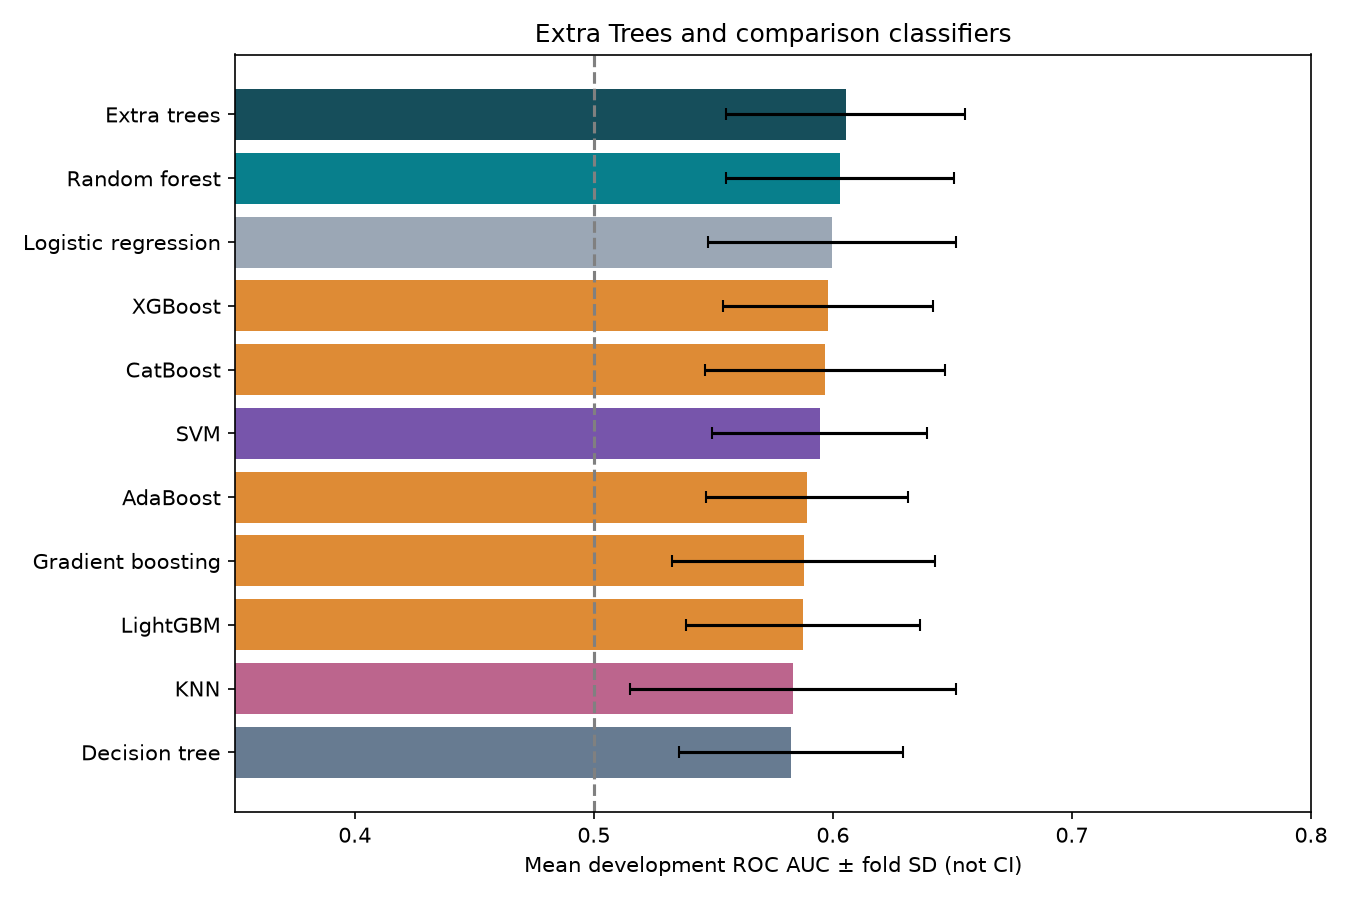

In [12]:
from train import ranked
ranked_cv = ranked(cv)
display(ranked_cv[['model','role','family','feature_set','candidate','mean_roc_auc','std_roc_auc','mean_average_precision']])
display(selection)
assert int(ranked_cv.iloc[0].spec_id) == selection['spec_id']
assert selection['test_used_for_selection'] is False
assert selection['focal_model'] == 'Extra trees'
print('Chosen:', selection['selected_model'], '/', selection['feature_set'])
display(Image(filename=str(REPORTS / 'comparison.png')))

### Selection conclusion
The ranking above identifies the best complete recipe under the declared development criterion. Extra Trees is the focal study method, but the selection code does not force it to win. Compare matched base/engineered configurations in `cv_candidates.csv` and the representation ablation before deciding whether added features earn their complexity. Fold variability and a winning mean do not establish statistical or universal superiority. The current model card and generated reports describe this run. Historical measurements are not substituted for it.

## 8. Evaluate the frozen winner
Only the selected model is fitted for the new holdout report. The prior baseline is a constant development-prevalence reference, not a competing trained algorithm. All precision/recall/F1 values use source Final code 1 as positive and threshold 0.50. Bootstrap intervals describe the fixed fitted model; they exclude full-search/selection and prevalence uncertainty. The historical holdout is internal research evidence.

1000 fixed-model class-stratified bootstrap samples; does not cover model selection or prevalence uncertainty


,metric,selected_model,prior_baseline,lower_95_percent,upper_95_percent
0,roc_auc,0.661228,0.500000,0.590221,0.731325
1,average_precision,0.533530,0.388430,0.460753,0.620867
2,accuracy,0.632231,0.611570,0.590909,0.673554
3,balanced_accuracy,0.553767,0.500000,0.509776,0.599208
4,precision,0.575758,0.000000,0.424213,0.724138
5,recall,0.202128,0.000000,0.127660,0.287234
6,f1,0.299213,0.000000,0.198473,0.400000
7,brier,0.221185,0.237552,0.208359,0.233710
8,log_loss,0.634214,0.668041,0.604958,0.664716


,Predicted code 2,Predicted code 1
Actual code 2,134,14
Actual code 1,75,19


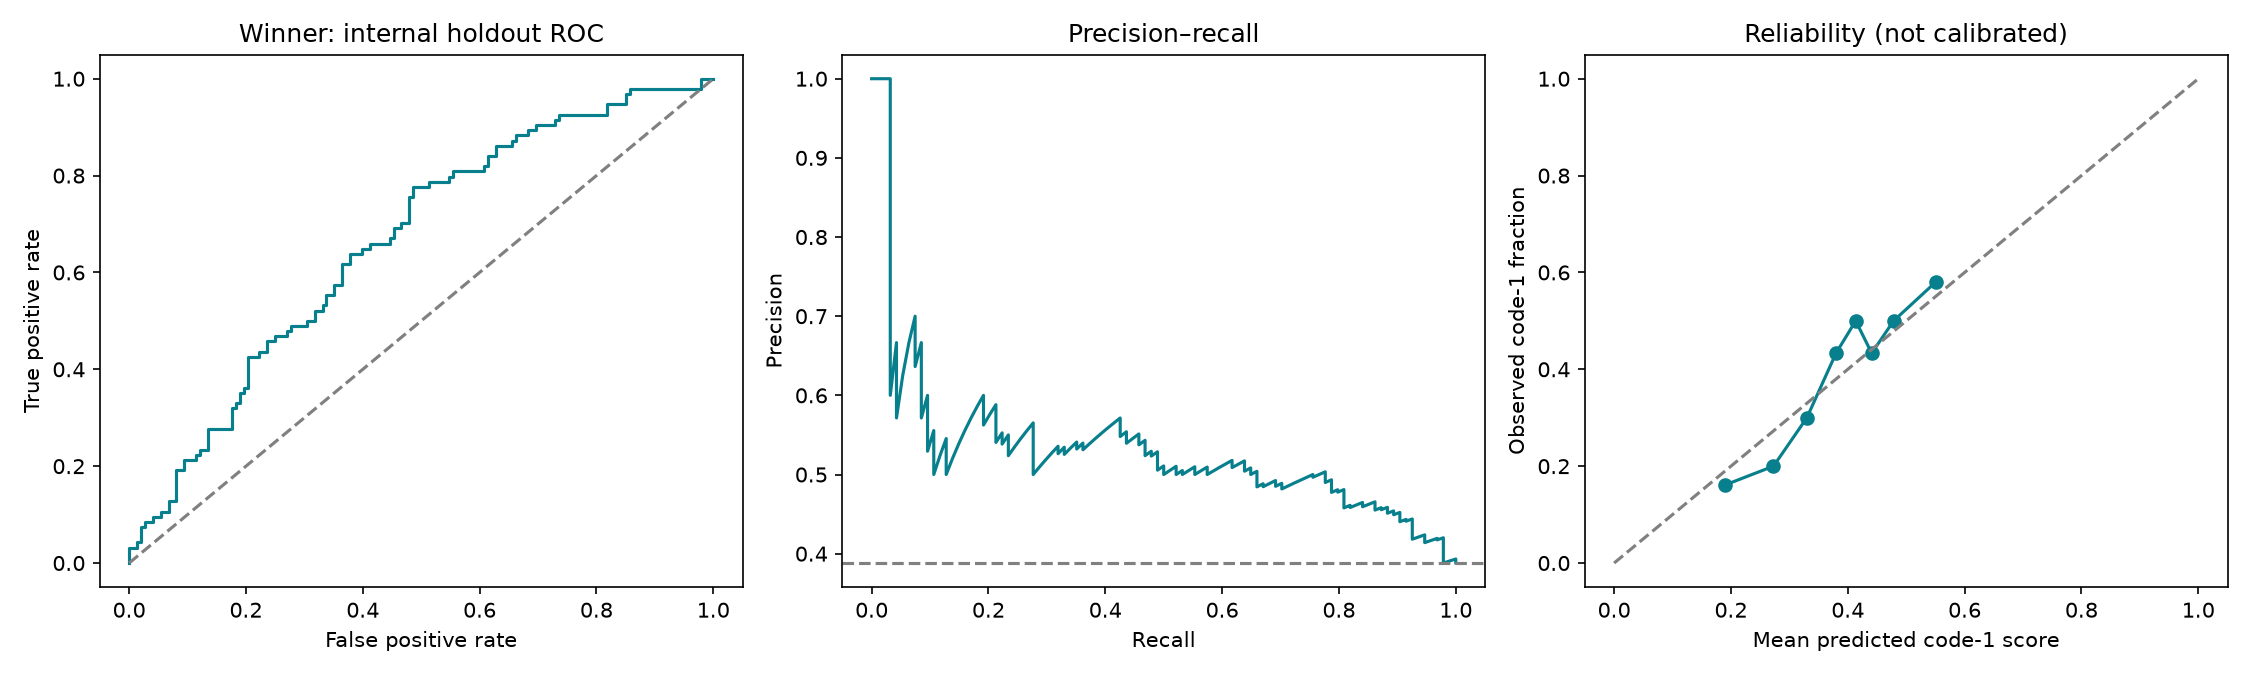

In [13]:
display(pd.DataFrame([{'metric':k, 'selected_model':v, 'prior_baseline':test['baseline_metrics'][k],
    'lower_95_percent':test['confidence_intervals'][k][0], 'upper_95_percent':test['confidence_intervals'][k][1]} for k,v in test['metrics'].items()]))
display(pd.DataFrame(test['confusion_matrix'], index=['Actual code 2','Actual code 1'], columns=['Predicted code 2','Predicted code 1']))
display(Image(filename=str(REPORTS / 'evaluation.png')))
print(test['confidence_interval_method'])

### Interpretation
Read ROC AUC together with average precision and code-1 prevalence. Inspect false negatives and recall at the fixed 0.50 threshold, rather than treating above-chance ranking as adequate performance. The reliability plot is descriptive; outputs are uncalibrated. A future operating threshold needs verified outcome meaning and an explicit objective, chosen using development data and followed by independent evaluation.

## 9. Explain the chosen model after selection
### Global: original-feature permutation importance
Shuffle each original input on the internal holdout and measure the decrease in ROC AUC, repeating ten times. The full pipeline is rerun, preserving dependencies with any derived fields. Importance follows selection and does not drive post-test feature removal. Error bars show shuffle SD, not causal uncertainty. Correlated inputs can share/mask importance and negative values can occur.

,feature,mean_auc_drop,shuffle_std
0,Neckstiffnessad,0.073871,0.021822
1,Cnsuffusionad,0.011149,0.004271
2,Headachead,0.009567,0.003825
3,DBPadd,0.008654,0.008213
4,Stagnantwaterexposure,0.005470,0.002172
5,Chillsad,0.005104,0.003040
6,Sex,0.004967,0.005959
7,Otheragriexposure,0.004025,0.003799
8,SBPadd,0.003623,0.006953
9,Paddyfieldexposure,0.003457,0.003488


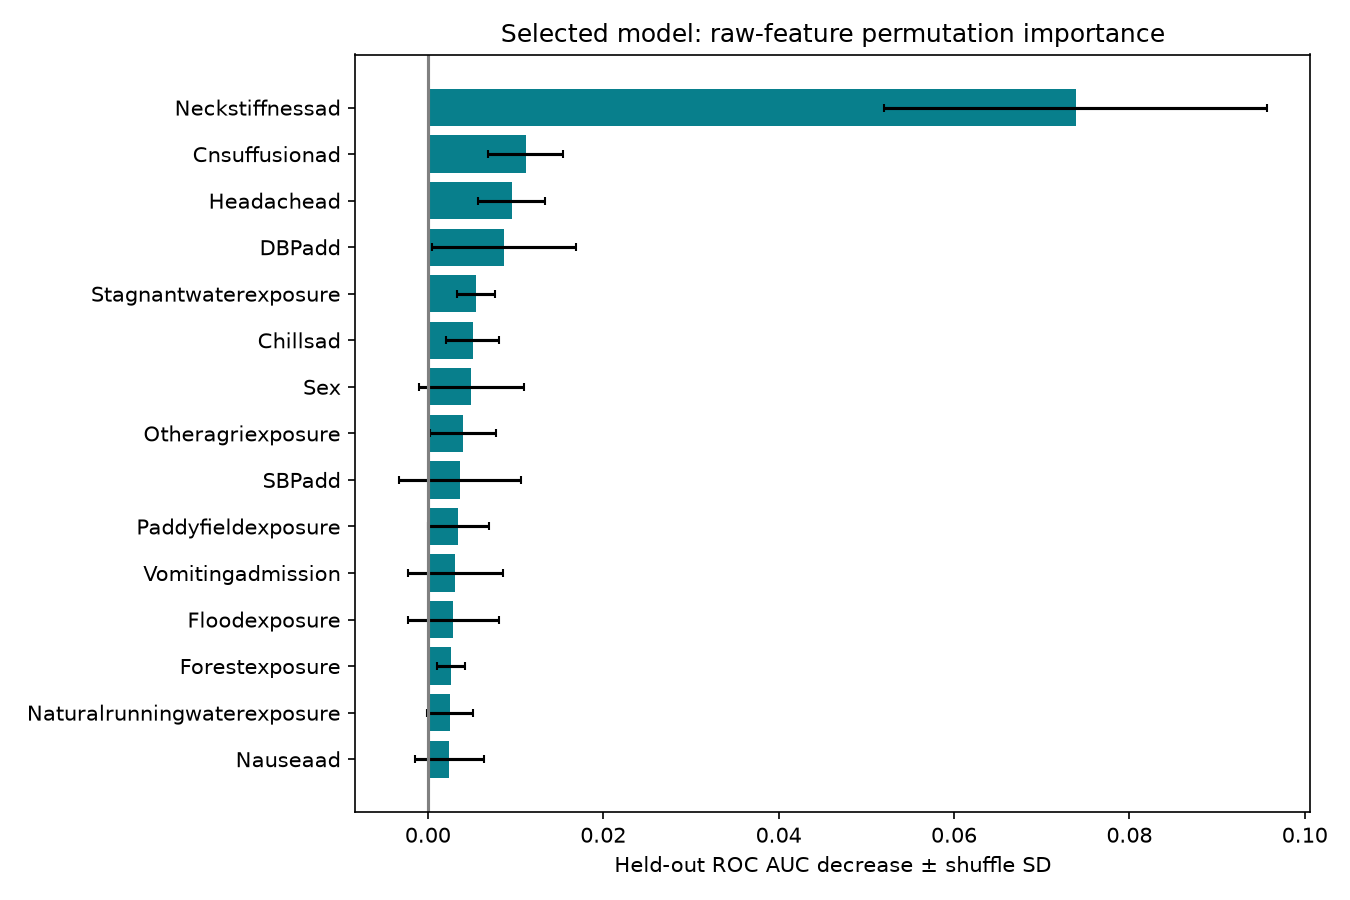

In [14]:
display(pd.read_csv(REPORTS / 'permutation_importance.csv'))
display(Image(filename=str(REPORTS / 'importance.png')))

### Local: reference-based Monte Carlo Shapley explanation
Use 24 random feature orders against one synthetic reference: development numeric medians and all source categories missing. Each order replaces reference values with example values and records marginal changes in code-1 probability. The average is a finite-permutation approximation; contributions telescope so baseline plus their sum reconstructs the prediction. This is a baseline-substitution game, not conditional population SHAP. Contributions depend on the reference, substitutions can be uncommon, and no causal or clinical interpretation follows.

Baseline 0.207422 + sum -0.130199 = prediction 0.077223


,feature,contribution,order_sampling_std
3,DBPadd,-0.057749,0.000562
1,PRad,-0.049762,0.003033
2,SBPadd,-0.030261,0.000562
5,Feverad,0.008456,0.003006
0,Age,-0.000882,0.000922
4,Sex,0.000000,0.000000
6,Headachead,0.000000,0.000000
7,Chillsad,0.000000,0.000000
8,Rigorsad,0.000000,0.000000
9,Musclepainad,0.000000,0.000000


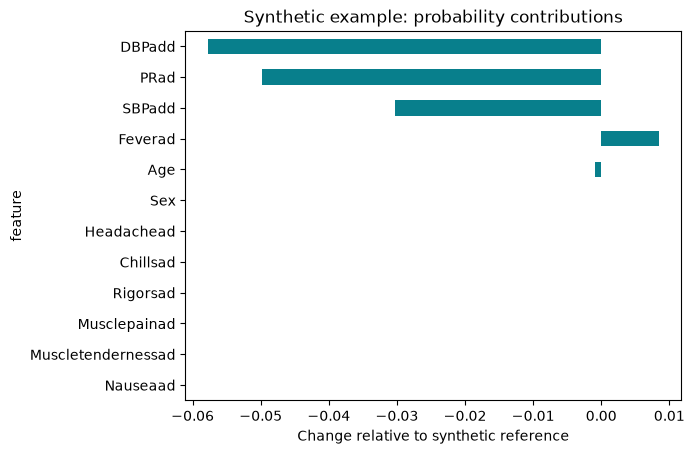

In [15]:
from src.explain import local_shapley
example = validate_record({'Age':35, 'Feverad':1})
base, predicted, local = local_shapley(model, example, reference)
print(f'Baseline {base:.6f} + sum {local.contribution.sum():+.6f} = prediction {predicted:.6f}')
assert np.isclose(base + local.contribution.sum(), model.predict_proba(example)[0,1])
display(local)
ax = local.head(12).iloc[::-1].plot.barh(x='feature', y='contribution', color='#087f8c', legend=False, title='Synthetic example: probability contributions')
ax.set_xlabel('Change relative to synthetic reference')
import matplotlib.pyplot as plt
plt.show()

### Synthetic one-feature response
The curve varies age with Feverad=1, other source categories missing and other numerics at development medians. This one fixed synthetic context is not a population effect and exposes no actual patient row.

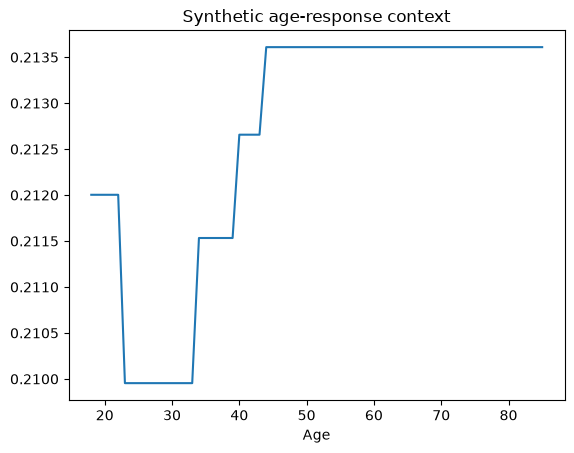

In [16]:
response = pd.read_csv(REPORTS / 'synthetic_age_response.csv')
response.plot(x='Age', y='code1_probability', title='Synthetic age-response context', legend=False)
plt.show()

## 10. Reproducibility and research extensions
The local manifest records data/code/package/report hashes, seed and selected representation. Raw data and generated research outputs remain local. The reviewed fitted serving release and aggregate or synthetic evidence are included in demo-app/. The loader verifies model/report bytes and package compatibility; load only your own trusted generated artifacts.

To extend the experiment, declare new recipes in `src/models.py` or change the feature contract in `src/data.py`. Preserve fold-local preprocessing and the declared focal-method comparison, use a new output directory, and obtain independent validation instead of repeatedly tuning against the historical holdout.

In [17]:
display({k:manifest[k] for k in ['model_version','model','feature_set','created_utc','python','source_data_sha256','packages']})

{'model_version': '503bc9aeb6f8',
 'model': 'Extra trees',
 'feature_set': 'base',
 'created_utc': '2026-10-25T11:47:15.660234+00:00',
 'python': '3.12.14',
 'source_data_sha256': '8f15e42cf808f6c342b868995633eedac86a7648cc73f553c852191424e7e880',
 'packages': {'numpy': '2.5.3',
  'pandas': '3.0.6',
  'scikit-learn': '1.9.1',
  'scipy': '1.18.1',
  'joblib': '1.6.0',
  'xgboost': '3.4.1',
  'lightgbm': '4.7.0',
  'catboost': '1.2.10'}}

## 11. Selected model card and limitations
The model card below describes the current Extra Trees comparison run. The focal-method rationale is in docs/EXTRA_TREES.md. Historical results are not substituted for this run.

In [18]:
display(Markdown((REPORTS / 'MODEL_CARD.md').read_text(encoding='utf-8')))

# Selected model: Extra trees

Academic comparison using admission inputs to predict numerical Final code 1 versus code 2.
Research demonstration only. Final code 1 and code 2 have unverified clinical meanings. The 99 missing-value convention and measurement units are provisional. Scores are uncalibrated model outputs, not clinical risks.

## Focal algorithm and comparison scope

**Extra Trees (Extremely Randomized Trees)** is the focal extension beyond the
originally supplied model list. It samples candidate split thresholds at random,
then chooses the best of those candidates. This run uses 150 trees, minimum leaf
size 10, square-root feature sampling and bootstrap=False. Confirm its lecture
coverage against the course syllabus before claiming it was not taught.

Logistic Regression, Decision Tree, Random Forest, SVM, KNN, XGBoost, AdaBoost,
Gradient Boosting, LightGBM and CatBoost provide comparisons. Linear Regression
is reserved for continuous targets and is not fitted to this binary target. The prior
reference is a constant development-prevalence score, not a candidate estimator.

38 configurations compare base and engineered features on
the same five stratified development folds. All learned preprocessing is fold-local.
Selection maximizes mean development ROC AUC, using average precision for exact ties,
then deterministic ordering. The holdout selects neither model nor features nor threshold.

Selected representation: **base**, candidate 0.
Development ROC AUC: **0.6054**; fold SD:
**0.0500**; average precision: **0.4920**.
Fold SD is not a confidence interval. Consult cv_candidates.csv and feature_ablation.csv
for the full comparison and representation evidence.

## Internal holdout evaluation

Eligible records: 1206; development: 964;
holdout: 242. Threshold: 0.50.

| Metric | Selected model | Constant prior reference |
|---|---:|---:|
| roc_auc | 0.6612 | 0.5000 |
| average_precision | 0.5335 | 0.3884 |
| accuracy | 0.6322 | 0.6116 |
| balanced_accuracy | 0.5538 | 0.5000 |
| precision | 0.5758 | 0.0000 |
| recall | 0.2021 | 0.0000 |
| f1 | 0.2992 | 0.0000 |
| brier | 0.2212 | 0.2376 |
| log_loss | 0.6342 | 0.6680 |

Confusion matrix (actual rows, predicted columns; code 2, code 1):
**[[134, 14], [75, 19]]**. ROC AUC 95% fixed-model bootstrap interval:
**[0.5902, 0.7313]**. This excludes selection uncertainty.

## Explanations and limitations

Ten-repeat raw-feature permutation importance follows selection. Local explanations
use 24 random feature orders against a synthetic median/missing reference; reference
score plus contributions reconstructs the prediction. These are model explanations,
not causal effects. See explainability.json and the synthetic explanation CSV.

Historical internal holdout already used in the earlier project; not independent external validation.
Outcome semantics, units and missing-value codes remain provisional. Low recall,
uncalibrated scores, cohort selection, correlated predictors, recording practices,
selection optimism and hospital/time shifts limit interpretation. Independent validation
is required before stronger claims. Patient data are not included in the saved release.


## Sources
- Suneth Agampodi (2022), [Mendeley Data v4](https://data.mendeley.com/datasets/zmxmp42g9p/4), DOI 10.17632/zmxmp42g9p.4, CC BY 4.0. Obtain data directly from the publisher; no data is redistributed here.
- [scikit-learn permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html): score-based model inspection and limitations.
- [Extra Trees rationale and configuration](../docs/EXTRA_TREES.md).
- [scikit-learn: Extremely Randomized Trees](https://scikit-learn.org/stable/modules/ensemble#extremely-randomized-trees).